# Food delivery time: exploring the data

Uses the same cleaning code as training, so what you see here is what the model sees.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from delivery_eta.data import load_training_orders

ROOT = Path.cwd() if Path("data").is_dir() else Path.cwd().parent
orders, report = load_training_orders(ROOT / "data" / "raw" / "train.csv")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
report

CleaningReport(rows_read=45593, rows_usable=41953, rejected={'no location recorded': 3640}, fixed={'flipped coordinate signs': 431, 'order time estimated from pickup': 1731, 'impossible rider details blanked': 91, 'unknown vehicle condition blanked': 520})

## Delivery times

count    41953.0
mean        26.3
std          9.4
min         10.0
25%         19.0
50%         26.0
75%         32.0
max         54.0
Name: minutes, dtype: float64

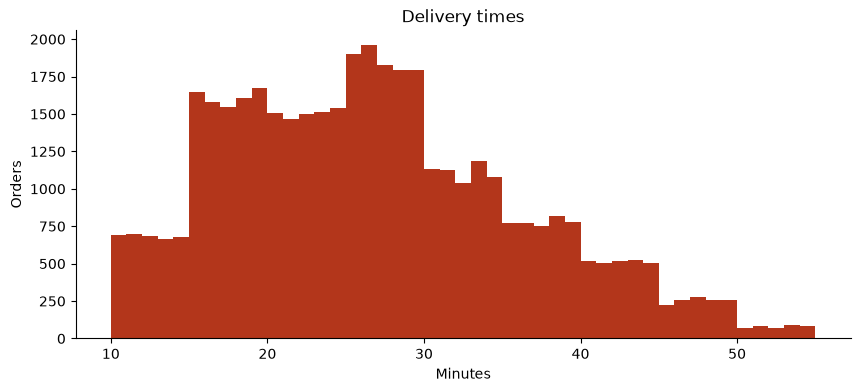

In [2]:
ax = orders["minutes"].plot.hist(bins=range(10, 56), color="#b3361b")
ax.set(title="Delivery times", xlabel="Minutes", ylabel="Orders")
orders["minutes"].describe().round(1)

## What is missing

In [3]:
missing = orders.isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("orders").assign(
    share=lambda t: (t["orders"] / len(orders)).map("{:.1%}".format)
)

,orders,share
rider_rating,1844,4.4%
rider_age,1800,4.3%
city,1114,2.7%
other_deliveries,905,2.2%
weather,569,1.4%
traffic,555,1.3%
vehicle_condition,481,1.1%
festival,215,0.5%


## Average time by category

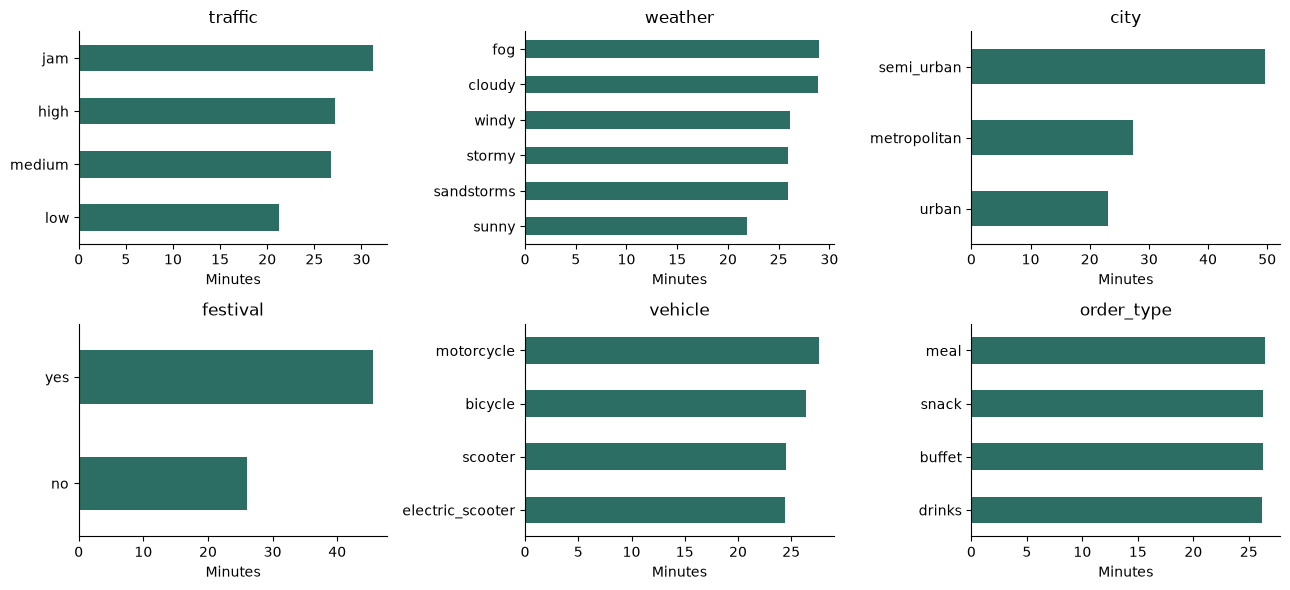

In [4]:
names = ["traffic", "weather", "city", "festival", "vehicle", "order_type"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, name in zip(axes.flat, names):
    orders.groupby(name)["minutes"].mean().sort_values().plot.barh(ax=ax, color="#2c6e63", title=name)
    ax.set(xlabel="Minutes", ylabel="")
plt.tight_layout()

## Distance, rider's age and rating

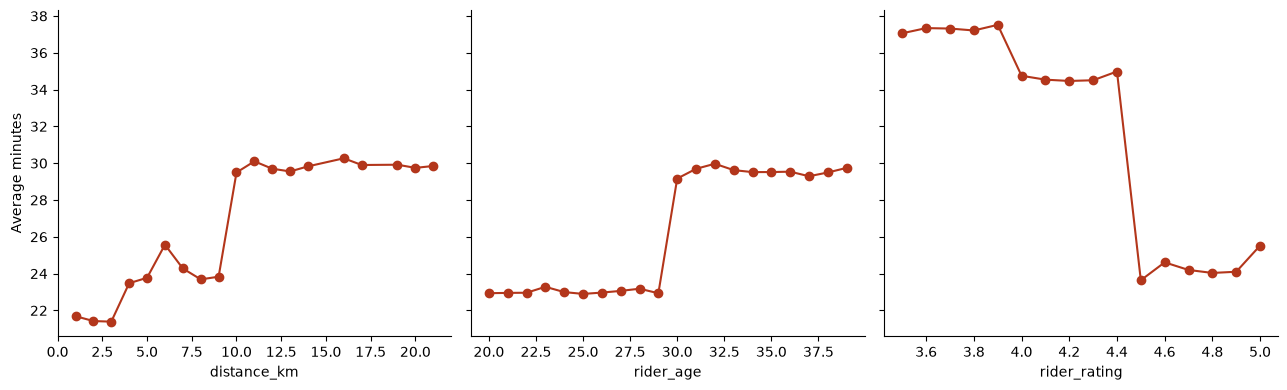

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
orders.groupby(orders["distance_km"].round())["minutes"].mean().plot(ax=axes[0], marker="o", color="#b3361b")
orders.groupby("rider_age")["minutes"].mean().plot(ax=axes[1], marker="o", color="#b3361b")
orders[orders["rider_rating"] >= 3.5].groupby("rider_rating")["minutes"].mean().plot(ax=axes[2], marker="o", color="#b3361b")
axes[0].set_ylabel("Average minutes")
plt.tight_layout()

## Signs that the data is artificial

Real orders don't look like this, which is why the model card says to retrain on your own orders before making promises to customers.

- **Age:** times jump by about 6 minutes exactly at 30, and are flat on both sides.
- **Traffic:** almost entirely decided by the hour.
- **Distance:** comes in fixed steps, with some steps never seen in some traffic.

In [6]:
pd.crosstab(orders["order_hour"].astype(int), orders["traffic"])

traffic,high,jam,low,medium
order_hour,,,,
0,0,0,408,0
8,0,0,1724,0
9,0,0,1848,0
10,0,0,1869,0
11,1658,0,181,0
12,847,0,0,0
13,738,0,0,0
14,748,0,0,0
15,80,0,0,741


In [7]:
orders.groupby("rider_age")["minutes"].mean().round(1).to_frame().T

rider_age,20.0,21.0,22.0,23.0,24.0,25.0,26.0,27.0,28.0,29.0,30.0,31.0,32.0,33.0,34.0,35.0,36.0,37.0,38.0,39.0
minutes,22.9,23.0,23.0,23.3,23.0,22.9,23.0,23.1,23.2,22.9,29.2,29.7,30.0,29.6,29.5,29.5,29.5,29.3,29.5,29.7
